In [1]:
#Import Packages
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import yfinance as yf

In [2]:
from pathlib import Path

def find_project_root():
    here = Path.cwd()
    for folder in [here, *here.parents]:
        if (folder / "data" / "raw").exists():
            return folder
    raise FileNotFoundError("Couldn't find data/raw above this notebook")

PROJECT_ROOT = find_project_root()
RAW = PROJECT_ROOT / "data" / "raw"
PROCESSED = PROJECT_ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

print(PROJECT_ROOT)   # should print ...\Drug R&D EDA

c:\Users\HP\drug-rnd-eda


In [3]:
#Load the data

rnd_df = pd.read_csv(RAW/ "rd_spend_all.csv")
df0 = pd.read_csv(RAW / "fda_approvals_raw.csv")
df1 = pd.read_csv(RAW / "company_size_all.csv")
df2 = pd.read_csv(RAW / "pipeline_size.csv")



In [4]:
##Inspect the data##

print(rnd_df.shape)
print(df0.shape)
print(df1.shape)
print(df2.shape)

print(rnd_df.head())
print(df0.head())
print(df1.head())
print(df2.head())

print(rnd_df.info())
print(df0.info())
print(df1.info())
print(df2.info())




(98, 4)
(15734, 12)
(111, 4)
(375, 7)
   year  rd_spend_usd_m ticker          company
0  2022             0.0    JNJ  Johnson Johnson
1  2023           483.0    JNJ  Johnson Johnson
2  2024          1841.0    JNJ  Johnson Johnson
3  2007          4882.8    MRK            Merck
4  2008          4805.0    MRK            Merck
  application_number app_type   sponsor_name               brand_name  \
0         ANDA070358      AND         ROXANE                 DIAZEPAM   
1         ANDA089427      AND  PUREPAC PHARM             DIPYRIDAMOLE   
2         ANDA075476      AND         SANDOZ  CARTEOLOL HYDROCHLORIDE   
3         ANDA070357      AND         ROXANE                 DIAZEPAM   
4         ANDA070356      AND         ROXANE                 DIAZEPAM   

        active_ingredients     dosage_form       route marketing_status  \
0                 DIAZEPAM          TABLET        ORAL     Discontinued   
1             DIPYRIDAMOLE          TABLET        ORAL     Discontinued   
2  CARTEOL

In [5]:
## Inspect the data types and missing values##

print(rnd_df.dtypes)
print(df0.dtypes)
print(df1.dtypes)
print(df2.dtypes)

print(rnd_df.isnull().sum())
print(df0.isnull().sum())
print(df1.isnull().sum())
print(df2.isnull().sum())

year                int64
rd_spend_usd_m    float64
ticker                str
company               str
dtype: object
application_number      str
app_type                str
sponsor_name            str
brand_name              str
active_ingredients      str
dosage_form             str
route                   str
marketing_status        str
approval_date           str
approval_year         int64
review_priority         str
submission_class        str
dtype: object
ticker               str
company              str
year               int64
revenue_usd_m    float64
dtype: object
ticker                   str
company                  str
year                   int64
phase1_trials          int64
phase2_trials          int64
phase3_trials          int64
total_active_trials    int64
dtype: object
year              0
rd_spend_usd_m    0
ticker            0
company           0
dtype: int64
application_number       0
app_type                 0
sponsor_name             0
brand_name               2


In [6]:
df0 = df0[df0["app_type"].isin(["NDA", "BLA"])]

In [7]:
## Aggregate FDA approvals to approvals per year##

#First aggregate approvals count per sponsor
df0_agg = df0.groupby(['sponsor_name', 'approval_year']).size().reset_index(name='approvals_count')

#then aggregate approvals count per year per sponsor
df0_agg_year = df0_agg.groupby(['approval_year']).size().reset_index(name='approvals_count_per_year')

print(df0_agg.head(30))
print(df0_agg_year.head())

                    sponsor_name  approval_year  approvals_count
0              60 DEGREES PHARMS           2018                1
1    A G L WELDING SUPPLY CO INC           2019                1
2   A-OX WELDING SUPPLY CO, INC.           2018                1
3   A-OX WELDING SUPPLY CO, INC.           2019                1
4                    AAA USA INC           2018                1
5                           AADI           2021                1
6                         ABBOTT           2002                1
7                         ABBVIE           2000                5
8                         ABBVIE           2001                5
9                         ABBVIE           2002                4
10                        ABBVIE           2003                2
11                        ABBVIE           2004                2
12                        ABBVIE           2005                3
13                        ABBVIE           2007                1
14                       

In [8]:
## Filter relevant companies and bridge to tickers for the analysis##

# See every unique sponsor name in the FDA data
all_sponsors = df0_agg["sponsor_name"].unique()

# Search for each company by keyword to find all their variants
keywords = ["pfizer", "lilly", "merck", "abbvie", "johnson", 
            "bristol", "amgen", "gilead", "biogen", "regeneron",
            "astra", "novartis", "roche", "sanofi", "glaxo"]

for kw in keywords:
    matches = [s for s in all_sponsors if kw.lower() in s.lower()]
    print(f"\n{kw.upper()}: {matches}")


PFIZER: ['KING PFIZER', 'PFIZER', 'PFIZER INC', 'PFIZER IRELAND PHARMACEUTICALS', 'PFIZER LABS']

LILLY: ['ELI LILLY AND CO', 'ELI LILLY CO', 'LILLY']

MERCK: ['MERCK', 'MERCK AND CO INC', 'MERCK SHARP DOHME', 'MSD MERCK CO', 'MSD SUB MERCK']

ABBVIE: ['ABBVIE', 'ABBVIE ENDOCRINE', 'ABBVIE INC']

JOHNSON: ['JOHNSON JOHNSON VISN']

BRISTOL: ['BRISTOL', 'BRISTOL MYERS SQUIBB', 'BRISTOL-MYERS', 'BRISTOL-MYERS SQUIBB']

AMGEN: ['AMGEN', 'AMGEN INC', 'ONYX PHARMS AMGEN']

GILEAD: ['GILEAD', 'GILEAD SCIENCES', 'GILEAD SCIENCES INC']

BIOGEN: ['BIOGEN', 'BIOGEN IDEC', 'BIOGEN IDEC INC', 'BIOGEN INC', 'BIOGEN MA', 'BIOGEN US']

REGENERON: ['REGENERON PHARMACEUTICALS']

ASTRA: ['ASTRAZENECA', 'ASTRAZENECA AB', 'ASTRAZENECA LP', 'ASTRAZENECA UK LTD']

NOVARTIS: ['NOVARTIS', 'NOVARTIS PHARM', 'NOVARTIS PHARMS', 'NOVARTIS PHARMS CORP']

ROCHE: ['HOFFMAN-LA ROCHE', 'HOFFMANN LA ROCHE', 'HOFFMANN-LA ROCHE', 'ROCHE']

SANOFI: ['CHATTEM SANOFI', 'SANOFI', 'SANOFI AVENTIS US', 'SANOFI SYNTHELABO', 'SA

In [9]:
## Bridge Sponsor to ticker##

SPONSOR_TO_TICKER = {
    # PFIZER
    "KING PFIZER"                    : "PFE",
    "PFIZER"                         : "PFE",
    "PFIZER INC"                     : "PFE",
    "PFIZER IRELAND PHARMACEUTICALS" : "PFE",
    "PFIZER LABS"                    : "PFE",

    # ELI LILLY
    "ELI LILLY AND CO"               : "LLY",
    "ELI LILLY CO"                   : "LLY",
    "LILLY"                          : "LLY",

    # MERCK  (excluding MERCK KGAA — different company)
    "MERCK"                          : "MRK",
    "MERCK AND CO INC"               : "MRK",
    "MERCK SHARP DOHME"              : "MRK",
    "MSD MERCK CO"                   : "MRK",
    "MSD SUB MERCK"                  : "MRK",

    # ABBVIE
    "ABBVIE"                         : "ABBV",
    "ABBVIE ENDOCRINE"               : "ABBV",
    "ABBVIE INC"                     : "ABBV",

    # JOHNSON & JOHNSON
    "JOHNSON JOHNSON VISN"           : "JNJ",

    # BRISTOL-MYERS SQUIBB
    "BRISTOL"                        : "BMY",
    "BRISTOL MYERS SQUIBB"           : "BMY",
    "BRISTOL-MYERS"                  : "BMY",
    "BRISTOL-MYERS SQUIBB"           : "BMY",

    # AMGEN
    "AMGEN"                          : "AMGN",
    "AMGEN INC"                      : "AMGN",
    "ONYX PHARMS AMGEN"              : "AMGN",

    # GILEAD
    "GILEAD"                         : "GILD",
    "GILEAD SCIENCES"                : "GILD",
    "GILEAD SCIENCES INC"            : "GILD",

    # BIOGEN
    "BIOGEN"                         : "BIIB",
    "BIOGEN IDEC"                    : "BIIB",
    "BIOGEN IDEC INC"                : "BIIB",
    "BIOGEN INC"                     : "BIIB",
    "BIOGEN MA"                      : "BIIB",
    "BIOGEN US"                      : "BIIB",

    # REGENERON
    "REGENERON PHARMACEUTICALS"      : "REGN",

    # ASTRAZENECA  (excluding ASTRAL — unrelated)
    "ASTRAZENECA"                    : "AZN",
    "ASTRAZENECA AB"                 : "AZN",
    "ASTRAZENECA LP"                 : "AZN",
    "ASTRAZENECA UK LTD"             : "AZN",

    # NOVARTIS
    "NOVARTIS"                       : "NVS",
    "NOVARTIS PHARM"                 : "NVS",
    "NOVARTIS PHARMS"                : "NVS",
    "NOVARTIS PHARMS CORP"           : "NVS",

    # ROCHE
    "HOFFMAN-LA ROCHE"               : "RHHBY",
    "HOFFMANN LA ROCHE"              : "RHHBY",
    "HOFFMANN-LA ROCHE"              : "RHHBY",
    "ROCHE"                          : "RHHBY",

    # SANOFI
    "CHATTEM SANOFI"                 : "SNY",
    "SANOFI"                         : "SNY",
    "SANOFI AVENTIS US"              : "SNY",
    "SANOFI SYNTHELABO"              : "SNY",
    "SANOFI US SERVICES"             : "SNY",
    "SANOFI-AVENTIS US"              : "SNY",

    # GLAXOSMITHKLINE  (excluding GLAXO GRP — old pre-merger entity, ambiguous)
    "GLAXOSMITHKLINE"                : "GSK",
    "GLAXOSMITHKLINE CONS"           : "GSK",
    "GLAXOSMITHKLINE LLC"            : "GSK",
}

In [10]:
# Map sponsor names to tickers
df0_agg["ticker"] = df0_agg["sponsor_name"].map(SPONSOR_TO_TICKER)

# Filter to only our 15 companies (everything else becomes NaN from the map)
fda_15 = df0_agg[df0_agg["ticker"].notna()].copy()

# Sanity check — how many approvals survived the filter?
print(f"Total FDA records  : {len(df0_agg):,}")
print(f"After filter (15)  : {len(fda_15):,}")
print(f"\nApprovals per company:")
print(fda_15.groupby("ticker")["approvals_count"].sum().sort_values(ascending=False))

Total FDA records  : 2,134
After filter (15)  : 290

Approvals per company:
ticker
ABBV     74
NVS      74
AZN      50
PFE      40
BMY      39
LLY      36
MRK      35
SNY      32
GILD     32
AMGN     26
GSK      22
BIIB     11
RHHBY    10
REGN      8
JNJ       1
Name: approvals_count, dtype: int64


In [11]:
## Check the distribution of application types for the filtered sponsors
df0[df0["sponsor_name"].isin(SPONSOR_TO_TICKER)]["app_type"].value_counts()

app_type
NDA    388
BLA    102
Name: count, dtype: int64

In [12]:
### Aggregate FDA approvals to approvals per year for the filtered sponsors##
approvals_per_year = (
    fda_15
    .groupby(["ticker","approval_year"])["approvals_count"].sum()
    .reset_index(name="approvals_count")
    .rename(columns={"approval_year": "year"})
)

print(approvals_per_year.head(20))
print(f"\nShape: {approvals_per_year.shape}")



   ticker  year  approvals_count
0    ABBV  2000                5
1    ABBV  2001                5
2    ABBV  2002                5
3    ABBV  2003                2
4    ABBV  2004                2
5    ABBV  2005                3
6    ABBV  2007                1
7    ABBV  2008                5
8    ABBV  2009                6
9    ABBV  2010                6
10   ABBV  2011                2
11   ABBV  2012                2
12   ABBV  2013                3
13   ABBV  2014                3
14   ABBV  2015                7
15   ABBV  2016                3
16   ABBV  2017                2
17   ABBV  2018                1
18   ABBV  2019                3
19   ABBV  2020                2

Shape: (235, 3)


In [13]:
## Incomplete rnd_df##
# Load and combine multiple rnd_spend files

import glob

# 1. Load Macrotrends individual files (exclude rd_spend_all.csv)
mt_files = list(RAW.glob("rd_spend_*.csv"))
mt_files = [f for f in mt_files if "rd_spend_all" not in f.name]  # exclude the combined file
mt_df = pd.concat([pd.read_csv(f) for f in mt_files], ignore_index=True)
mt_df["source"] = "macrotrends"

# 2. Load EDGAR combined file
edgar_df = pd.read_csv(RAW / "rd_spend_all.csv")
edgar_df["source"] = "edgar"

# 3. Stack both dataframes
rnd_combined_df = pd.concat([mt_df, edgar_df], ignore_index=True)

# Sort so EDGAR rows come LAST within each ticker+year group
# Then keep="last" will always pick EDGAR when both exist
source_order = {"edgar": 1, "macrotrends": 0}
rnd_combined_df["source_rank"] = rnd_combined_df["source"].map(source_order)

rnd_combined_df = (rnd_combined_df
    .sort_values(["ticker", "year", "source_rank"])
    .drop_duplicates(subset=["ticker", "year"], keep="last")
    .drop(columns="source_rank")
    .reset_index(drop=True)
)
rnd_combined_df = rnd_combined_df.drop_duplicates(subset=["ticker", "year"], keep="last").reset_index(drop=True)

# 4. Quick check before joining
print(rnd_combined_df.groupby("source")["ticker"].count())
print(rnd_combined_df.shape)

source
edgar           98
macrotrends    105
Name: ticker, dtype: int64
(203, 5)


In [14]:
# Quick test on one ticker to confirm what yfinance actually returns
import yfinance as yf
stock = yf.Ticker("PFE")
print(stock.get_shares_full(start="2010-01-01").head(10))
print(type(stock.get_shares_full(start="2010-01-01")))

2015-11-24 00:00:00-05:00    6173500000
2016-03-16 00:00:00-04:00    6191880000
2016-05-12 00:00:00-04:00    6064850000
2016-08-11 00:00:00-04:00    6068360000
2016-08-11 00:00:00-04:00    6065650000
2016-11-11 00:00:00-05:00    5951870000
2016-11-11 00:00:00-05:00    6068350000
2016-11-11 00:00:00-05:00    6068360000
2017-02-23 00:00:00-05:00    5955130000
2017-02-23 00:00:00-05:00    5951870000
dtype: int64
<class 'pandas.Series'>


In [15]:
##Inspect yfinance market cap data for the 15 companies##
TICKERS = ["PFE","MRK","ABBV","LLY","BMY","AMGN",
           "BIIB","REGN","AZN","NVS","SNY","GSK", "JNJ","GILD","RHHBY"]

market_cap_rows = []

for ticker in TICKERS:
    print(f"  {ticker}", end=" ")
    stock = yf.Ticker(ticker)

    # Get shares history (returns a Series — date index, share count values)
    shares_history = stock.get_shares_full(start="2010-01-01")

    # Get annual year-end closing price
    stock_history = stock.history(period="max", interval="1y")
    # Fall back to daily history if annual history is unavailable
    if stock_history.empty:
        stock_history = stock.history(period="max", interval="1d")

    if not stock_history.empty:
        dates = pd.to_datetime(stock_history.index, errors="coerce")
        valid_dates = ~dates.isna()
        stock_history = stock_history.loc[valid_dates].copy()
        stock_history.index = dates[valid_dates]
        year_end_prices = stock_history.groupby(stock_history.index.year).last()
    else:
        year_end_prices = pd.DataFrame(columns=["Close"])

    if shares_history is None or shares_history.empty:
        print("→ no shares data")
        continue

    years_found = 0
    for year in year_end_prices.index:
        try:
            year_end_price = year_end_prices.loc[year, "Close"]

            # shares_history is a Series — filter by year, take last value
            year_shares = shares_history[shares_history.index.year == year]
            if year_shares.empty:
                continue
            shares_outstanding = year_shares.iloc[-1]  # last observation in that year

            market_cap_usd_m = round((year_end_price * shares_outstanding) / 1_000_000, 2)

            market_cap_rows.append({
                "ticker"          : ticker,
                "year"            : year,
                "market_cap_usd_m": market_cap_usd_m,
            })
            years_found += 1

        except Exception as e:
            continue

    print(f"→ {years_found} years")

mcap_df = pd.DataFrame(market_cap_rows)
print(f"\nShape: {mcap_df.shape}")
print(mcap_df.groupby("ticker")["year"].count())

  PFE 

$PFE: Invalid input - interval=1y is not supported. Valid intervals: , 2m, 5m, 15m, 30m, 60m, 90m, 1h, 4h, 1d, 5d, 1wk, 1mo, 3mo]


→ 12 years
  MRK 

$MRK: Invalid input - interval=1y is not supported. Valid intervals: , 2m, 5m, 15m, 30m, 60m, 90m, 1h, 4h, 1d, 5d, 1wk, 1mo, 3mo]


→ 12 years
  ABBV 

$ABBV: Invalid input - interval=1y is not supported. Valid intervals: , 2m, 5m, 15m, 30m, 60m, 90m, 1h, 4h, 1d, 5d, 1wk, 1mo, 3mo]


... (21 outputs left out)

$GILD: Invalid input - interval=1y is not supported. Valid intervals: , 2m, 5m, 15m, 30m, 60m, 90m, 1h, 4h, 1d, 5d, 1wk, 1mo, 3mo]


→ 12 years
  RHHBY 

$RHHBY: Invalid input - interval=1y is not supported. Valid intervals: , 2m, 5m, 15m, 30m, 60m, 90m, 1h, 4h, 1d, 5d, 1wk, 1mo, 3mo]


→ 10 years

Shape: (170, 3)
ticker
ABBV     12
AMGN     12
AZN      10
BIIB     12
BMY      12
GILD     12
GSK      10
JNJ      12
LLY      12
MRK      12
NVS      10
PFE      12
REGN     12
RHHBY    10
SNY      10
Name: year, dtype: int64


In [16]:
print(mcap_df.groupby("ticker").agg(
    min_year=("year","min"),
    max_year=("year","max"),
    count=("year","count")
))

        min_year  max_year  count
ticker                           
ABBV        2015      2026     12
AMGN        2015      2026     12
AZN         2017      2026     10
BIIB        2015      2026     12
BMY         2015      2026     12
GILD        2015      2026     12
GSK         2017      2026     10
JNJ         2015      2026     12
LLY         2015      2026     12
MRK         2015      2026     12
NVS         2017      2026     10
PFE         2015      2026     12
REGN        2015      2026     12
RHHBY       2017      2026     10
SNY         2017      2026     10


Valid market cap data on the 15 companies for the past 8-12 years each.

In [17]:
#Adjustments to biogen rnd spend data
biogen_rd = {
    2015: 2013, 2016: 1973, 2017: 2254, 2018: 2597, 2019: 2281,
    2020: 3991, 2021: 2501, 2022: 2231, 2023: 2462,
    2024: 2041
}

# name used for Biogen in your existing data
biogen_name = rnd_combined_df.loc[rnd_combined_df["ticker"] == "BIIB", "company"].iloc[0]

# remove the old Biogen rows, then add the corrected ones
rnd_combined_df = rnd_combined_df[rnd_combined_df["ticker"] != "BIIB"]
new_rows = pd.DataFrame({"year": list(biogen_rd.keys()),
                         "rd_spend_usd_m": list(biogen_rd.values())})
new_rows["ticker"] = "BIIB"
new_rows["company"] = biogen_name
new_rows["source"] = "10-K (manual)"
rnd_combined_df = pd.concat([rnd_combined_df, new_rows], ignore_index=True)

print(rnd_combined_df[rnd_combined_df["ticker"] == "BIIB"].sort_values("year"))

     year  rd_spend_usd_m ticker company         source
189  2015          2013.0   BIIB  Biogen  10-K (manual)
190  2016          1973.0   BIIB  Biogen  10-K (manual)
191  2017          2254.0   BIIB  Biogen  10-K (manual)
192  2018          2597.0   BIIB  Biogen  10-K (manual)
193  2019          2281.0   BIIB  Biogen  10-K (manual)
194  2020          3991.0   BIIB  Biogen  10-K (manual)
195  2021          2501.0   BIIB  Biogen  10-K (manual)
196  2022          2231.0   BIIB  Biogen  10-K (manual)
197  2023          2462.0   BIIB  Biogen  10-K (manual)
198  2024          2041.0   BIIB  Biogen  10-K (manual)


In [18]:
#Build master_df with left joins on ticker + year
# Step 1 — define your final company list and year range
FINAL_TICKERS = ["PFE","MRK","ABBV","LLY","BMY","AMGN",
                 "BIIB","REGN","AZN","NVS","SNY","GSK", "GILD"]
YEAR_MIN, YEAR_MAX = 2015, 2024
rnd_full = rnd_combined_df.copy()

# Step 2 — filter each source dataframe to final tickers + year range
# do this for: rnd_combined_df, mcap_df, pipeline_df, approvals_per_year
rnd_combined_df = rnd_combined_df[rnd_combined_df["ticker"].isin(FINAL_TICKERS) & rnd_combined_df["year"].between(YEAR_MIN, YEAR_MAX)]
mcap_df = mcap_df[mcap_df["ticker"].isin(FINAL_TICKERS) & mcap_df["year"].between(YEAR_MIN, YEAR_MAX)]
pipeline_df = df2[df2["ticker"].isin(FINAL_TICKERS) & df2["year"].between(YEAR_MIN, YEAR_MAX)]
approvals_per_year = approvals_per_year[approvals_per_year["ticker"].isin(FINAL_TICKERS) & approvals_per_year["year"].between(YEAR_MIN, YEAR_MAX)]

# Step 3 — rebuild master_df with left joins on ticker + year
# base = rnd_combined_df (your most complete source)
master_df = pd.merge(rnd_combined_df, mcap_df, on=["ticker", "year"], how="left")
master_df = pd.merge(master_df, df2, on=["ticker", "year"], how="left")
master_df = pd.merge(master_df, approvals_per_year, on=["ticker", "year"], how="left")

# Step 4 — fill NaN approvals with 0 (no match = zero approvals that year)
master_df["approvals_count"] = master_df["approvals_count"].fillna(0).astype(int)

master_df = master_df.drop(columns=["company_y"])
master_df = master_df.rename(columns={"company_x": "company"})

master_df = master_df.drop(columns=["source"])

print(master_df.head(10))
print(master_df.info())
print(f" Master_df.shape: {master_df.shape}")

   year  rd_spend_usd_m ticker company  market_cap_usd_m  phase1_trials  \
0  2015          4285.0   ABBV  Abbvie          62039.70             50   
1  2016          4385.0   ABBV  Abbvie          67712.56             51   
2  2017          5007.0   ABBV  Abbvie         100984.62             65   
3  2018         10329.0   ABBV  Abbvie          99368.70             68   
4  2019          6407.0   ABBV  Abbvie          99125.04             75   
5  2020          6379.0   ABBV  Abbvie         151140.74             84   
6  2021          6922.0   ABBV  Abbvie         200422.89             92   
7  2022          6510.0   ABBV  Abbvie         248624.09             96   
8  2023          7675.0   ABBV  Abbvie         247627.97            101   
9  2024         12791.0   ABBV  Abbvie         294594.93            104   

   phase2_trials  phase3_trials  total_active_trials  approvals_count  
0             64             77                  191                7  
1             65             8

In [19]:
print("Shape:", master_df.shape)
print("\nNull counts:")
print(master_df.isnull().sum())
print("\nYear range:", master_df["year"].min(), "–", master_df["year"].max())
print("\nTickers:", sorted(master_df["ticker"].unique()))
print("\nRows per ticker:")
print(master_df.groupby("ticker")["year"].count())

Shape: (123, 10)

Null counts:
year                   0
rd_spend_usd_m         0
ticker                 0
company                0
market_cap_usd_m       8
phase1_trials          0
phase2_trials          0
phase3_trials          0
total_active_trials    0
approvals_count        0
dtype: int64

Year range: 2015 – 2024

Tickers: ['ABBV', 'AMGN', 'AZN', 'BIIB', 'BMY', 'GILD', 'GSK', 'LLY', 'MRK', 'NVS', 'PFE', 'REGN', 'SNY']

Rows per ticker:
ticker
ABBV    10
AMGN    10
AZN     10
BIIB    10
BMY     10
GILD     5
GSK     10
LLY      8
MRK     10
NVS     10
PFE     10
REGN    10
SNY     10
Name: year, dtype: int64


In [20]:
# ADD R AND D spend lag period column
lag_table = rnd_full[["ticker", "year", "rd_spend_usd_m"]].copy()
lag_table["year"] = lag_table["year"] + 5          # spend from year X lines up with year X+5
lag_table = lag_table.rename(columns={"rd_spend_usd_m": "rd_spend_lag5"})

master_df = master_df.drop(columns="rd_spend_lag5", errors="ignore")
master_df = master_df.merge(lag_table, on=["ticker", "year"], how="left")

print(master_df["rd_spend_lag5"].notna().sum(), "of", len(master_df), "rows have a lag value")

110 of 123 rows have a lag value


In [21]:
# Handle market cap nulls
master_df["market_cap_usd_m"] = (
    master_df.groupby("ticker")["market_cap_usd_m"]
    .transform(lambda x: x.ffill().bfill())
)

print(master_df.shape)
print(master_df.isnull().sum())
print(master_df.columns.tolist())

(123, 11)
year                    0
rd_spend_usd_m          0
ticker                  0
company                 0
market_cap_usd_m        0
phase1_trials           0
phase2_trials           0
phase3_trials           0
total_active_trials     0
approvals_count         0
rd_spend_lag5          13
dtype: int64
['year', 'rd_spend_usd_m', 'ticker', 'company', 'market_cap_usd_m', 'phase1_trials', 'phase2_trials', 'phase3_trials', 'total_active_trials', 'approvals_count', 'rd_spend_lag5']


In [22]:
## Save the final master_df to CSV for future use
import os
os.makedirs("C:\\Users\\HP\\Drug R&D EDA\\data\\processed", exist_ok=True)
master_df.to_csv("C:\\Users\\HP\\Drug R&D EDA\\data\\processed\\master_df.csv", index=False)
print("✓ Saved.")

✓ Saved.


In [23]:
print(rnd_combined_df[rnd_combined_df["ticker"] == "BIIB"][["year", "rd_spend_usd_m"]].sort_values("year"))

     year  rd_spend_usd_m
189  2015          2013.0
190  2016          1973.0
191  2017          2254.0
192  2018          2597.0
193  2019          2281.0
194  2020          3991.0
195  2021          2501.0
196  2022          2231.0
197  2023          2462.0
198  2024          2041.0


# EXPLORATORY DATA ANALYSIS 

In [24]:
## SUMMARY STATISTICS ##
master_df.describe().round(2)

,year,rd_spend_usd_m,market_cap_usd_m,phase1_trials,phase2_trials,phase3_trials,total_active_trials,approvals_count,rd_spend_lag5
count,123.00,123.00,123.00,123.00,123.00,123.00,123.00,123.00,110.00
mean,2019.33,6899.54,123523.66,105.20,145.98,81.24,332.41,1.73,5449.07
std,2.86,3732.87,76635.82,61.47,101.79,34.62,187.32,1.63,2525.37
min,2015.00,1468.80,22283.35,11.00,14.00,19.00,52.00,0.00,489.25
25%,2017.00,4790.20,68260.98,57.50,75.00,56.50,209.50,1.00,3732.50
50%,2019.00,6332.00,102975.42,97.00,114.00,79.00,282.00,1.00,5555.15
75%,2022.00,9009.50,149900.32,149.50,197.50,106.50,450.00,3.00,6905.75
max,2024.00,30531.00,397864.21,257.00,431.00,166.00,824.00,7.00,11111.00


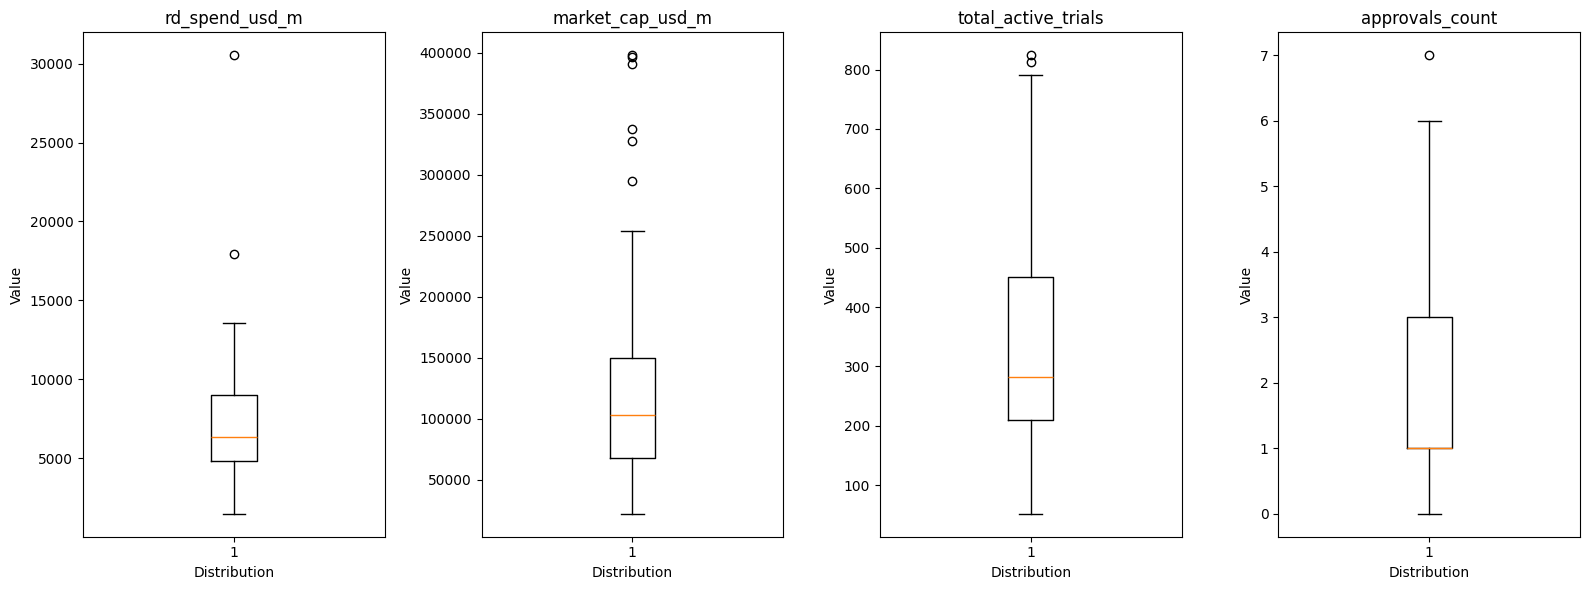

In [25]:
#Distribution of numeric columns
# columns to plot
numeric_cols = ["rd_spend_usd_m", "market_cap_usd_m", "total_active_trials", "approvals_count"]

fig, axes = plt.subplots(1, 4, figsize=(16, 6))

for ax, col in zip(axes, numeric_cols):
    # hint: ax.boxplot() or use master_df.boxplot()
    ax.boxplot(master_df[col])
    ax.set_title(col)
    ax.set_ylabel("Value")
    ax.set_xlabel("Distribution")
    pass

plt.tight_layout()
plt.show()

In [26]:
# Investigate outliers
print(master_df.nlargest(3, "rd_spend_usd_m")[["ticker", "year", "rd_spend_usd_m"]])
print(master_df.nlargest(3, "market_cap_usd_m")[["ticker", "year", "market_cap_usd_m"]])
print(master_df.nlargest(3, "total_active_trials")[["ticker", "year", "total_active_trials"]])

   ticker  year  rd_spend_usd_m
71    MRK  2023         30531.0
72    MRK  2024         17938.0
29    AZN  2024         13583.0
   ticker  year  market_cap_usd_m
28    AZN  2023         397864.21
29    AZN  2024         396287.40
27    AZN  2022         390330.23
   ticker  year  total_active_trials
71    MRK  2023                  824
70    MRK  2022                  812
69    MRK  2021                  791


In [27]:
# Flag Identified Outliers
master_df["is_outlier"] = (
    ((master_df["ticker"] == "MRK") & (master_df["year"].isin([2023, 2024]))) |
    ((master_df["ticker"] == "AZN") & (master_df["year"] >= 2022))
)

print(master_df["is_outlier"].value_counts())

is_outlier
False    118
True       5
Name: count, dtype: int64


In [28]:
master_df.to_csv(PROCESSED / "master_df.csv", index=False)
print("Saved.")

Saved.


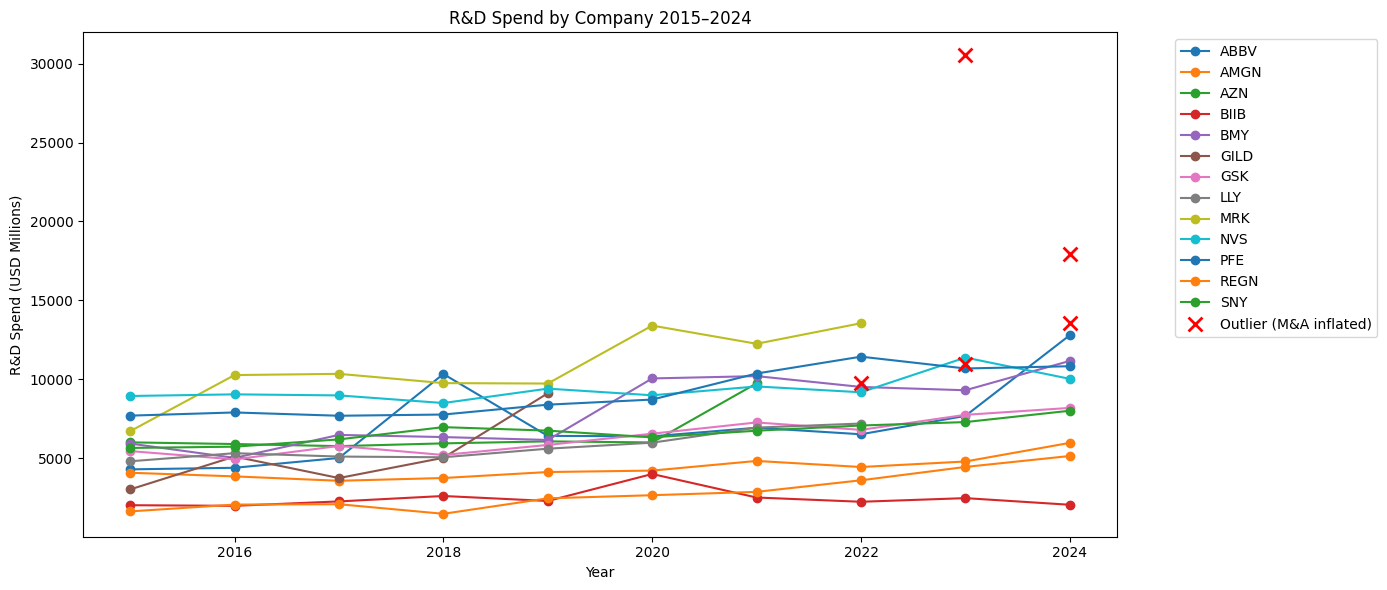

In [29]:
# Visualize R&D Spend by Company 2015–2024 with Outliers Marked
fig, ax = plt.subplots(figsize=(14, 6))

for ticker, group in master_df.groupby("ticker"):
    # plot year on x axis, rd_spend_usd_m on y axis
    # use different line style or marker for is_outlier rows
    clean = group[group["is_outlier"] == False]
    outlier = group[group["is_outlier"] == True]
    
    ax.plot(clean["year"], clean["rd_spend_usd_m"], marker="o", label=ticker)
    # add the outlier points differently — hint: ax.plot with marker="x", linestyle="--"

# mark outlier points
outliers = master_df[master_df["is_outlier"] == True]
ax.scatter(outliers["year"], outliers["rd_spend_usd_m"], 
           color="red", zorder=5, s=100, marker="x", 
           linewidths=2, label="Outlier (M&A inflated)")

ax.set_title("R&D Spend by Company 2015–2024")
ax.set_xlabel("Year")
ax.set_ylabel("R&D Spend (USD Millions)")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Spending splits into three groups. AbbVie, Bristol Myers Squibb and Lilly grew R&D fastest. Merck, Novartis, Pfizer and AstraZeneca spent steadily, and Regeneron and Biogen stayed modest.

Some spikes are acquisitions, not research. Merck's $30.5B (2023) and $17.9B (2024) followed the Prometheus and Imago deals, and AbbVie's 2018 and 2024 jumps followed Allergan, ImmunoGen and Cerevel. These company-years are flagged as outliers.

In [30]:
# 1. Does GILD have data through 2024?
print(master_df[master_df["ticker"]=="GILD"][["ticker","year","rd_spend_usd_m"]])

# 2. What are the top 3 year-on-year R&D spend increases?
master_df["rd_spend_yoy"] = master_df.groupby("ticker")["rd_spend_usd_m"].diff()
print(master_df.nlargest(3, "rd_spend_yoy")[["ticker","year","rd_spend_usd_m","rd_spend_yoy"]])

   ticker  year  rd_spend_usd_m
40   GILD  2015          3014.0
41   GILD  2016          5098.0
42   GILD  2017          3734.0
43   GILD  2018          5018.0
44   GILD  2019          9106.0
   ticker  year  rd_spend_usd_m  rd_spend_yoy
71    MRK  2023         30531.0       16983.0
3    ABBV  2018         10329.0        5322.0
9    ABBV  2024         12791.0        5116.0


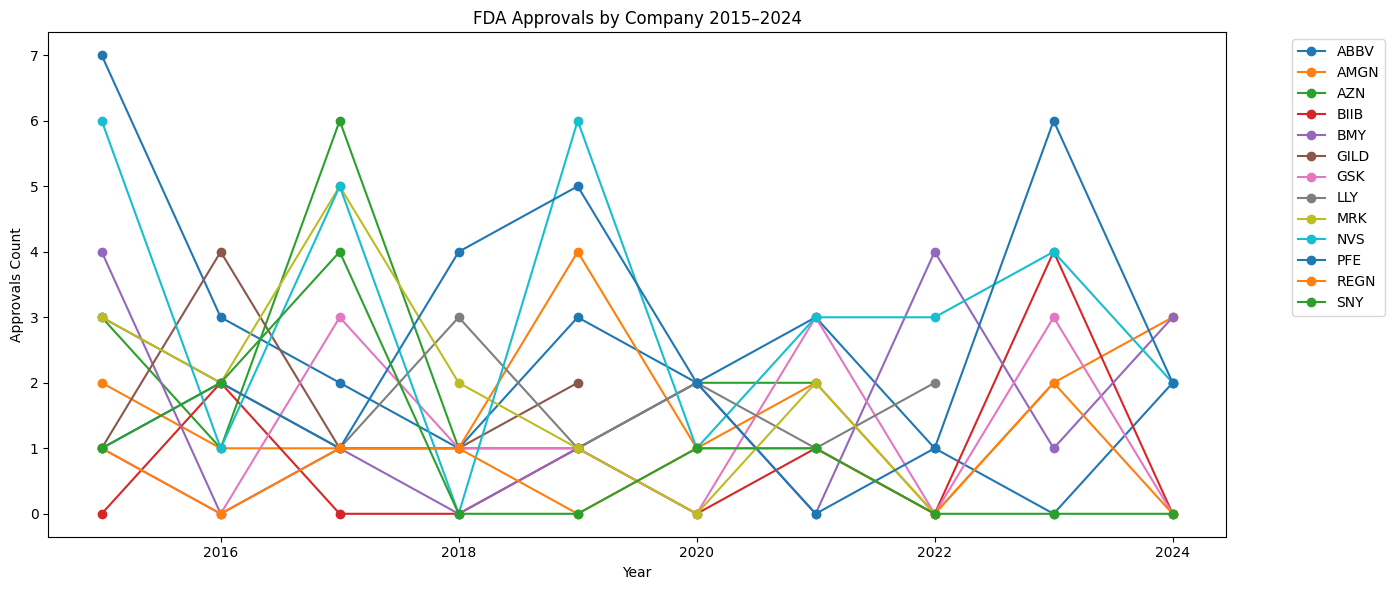

In [31]:
# Visualize FDA Approvals by Company 2015–2024 with Outliers Marked
fig, ax = plt.subplots(figsize=(14, 6))

for ticker, group in master_df.groupby("ticker"):
    clean = group[group["is_outlier"] == False]
    ax.plot(clean["year"], clean["approvals_count"], 
            marker="o", label=ticker)

ax.set_title("FDA Approvals by Company 2015–2024")
ax.set_xlabel("Year")
ax.set_ylabel("Approvals Count")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

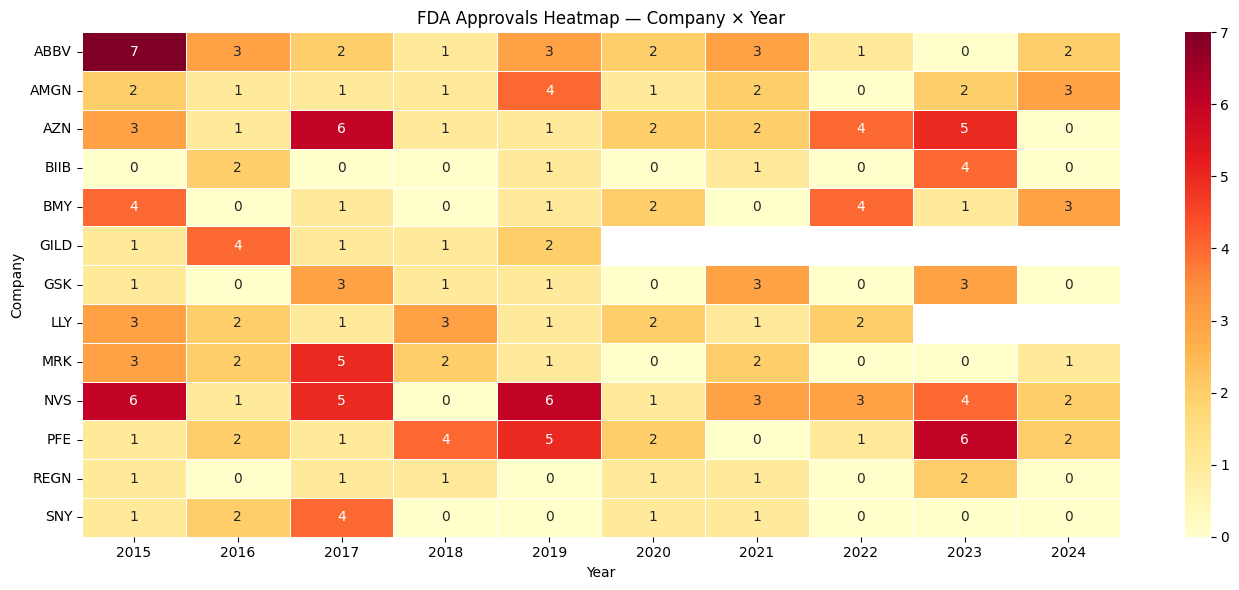

In [32]:
#Create a heatmap of FDA approvals by company and year
# Pivot the data: companies as rows, years as columns, approvals as values
approvals_pivot = master_df.pivot_table(
    index="ticker", 
    columns="year", 
    values="approvals_count", 
    aggfunc="sum"
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    approvals_pivot, 
    annot=True,        # show the numbers inside each cell
    fmt=".0f",         # no decimal places
    cmap="YlOrRd",     # yellow → orange → red, higher = darker
    linewidths=0.5,
    ax=ax
)
ax.set_title("FDA Approvals Heatmap — Company × Year")
ax.set_xlabel("Year")
ax.set_ylabel("Company")
plt.tight_layout()
plt.show()

In [33]:
# Total approvals per company across all years
total_approvals = (master_df.groupby("ticker")["approvals_count"]
                   .sum()
                   .sort_values(ascending=False)
                   .reset_index())
total_approvals.columns = ["ticker", "total_approvals"]
print(total_approvals)

   ticker  total_approvals
0     NVS               31
1     AZN               25
2    ABBV               24
3     PFE               24
4    AMGN               17
5     MRK               16
6     BMY               16
7     LLY               15
8     GSK               12
9     SNY                9
10   GILD                9
11   BIIB                8
12   REGN                7


In [34]:
# Count years per company, then calculate approval rate
years_per_company = master_df.groupby("ticker")["year"].count().reset_index()
years_per_company.columns = ["ticker", "years_covered"]

approval_rate = total_approvals.merge(years_per_company, on="ticker")
approval_rate["approvals_per_year"] = (
    approval_rate["total_approvals"] / approval_rate["years_covered"]
).round(2)

print(approval_rate.sort_values("approvals_per_year", ascending=False))

   ticker  total_approvals  years_covered  approvals_per_year
0     NVS               31             10                3.10
1     AZN               25             10                2.50
2    ABBV               24             10                2.40
3     PFE               24             10                2.40
7     LLY               15              8                1.88
10   GILD                9              5                1.80
4    AMGN               17             10                1.70
6     BMY               16             10                1.60
5     MRK               16             10                1.60
8     GSK               12             10                1.20
9     SNY                9             10                0.90
11   BIIB                8             10                0.80
12   REGN                7             10                0.70


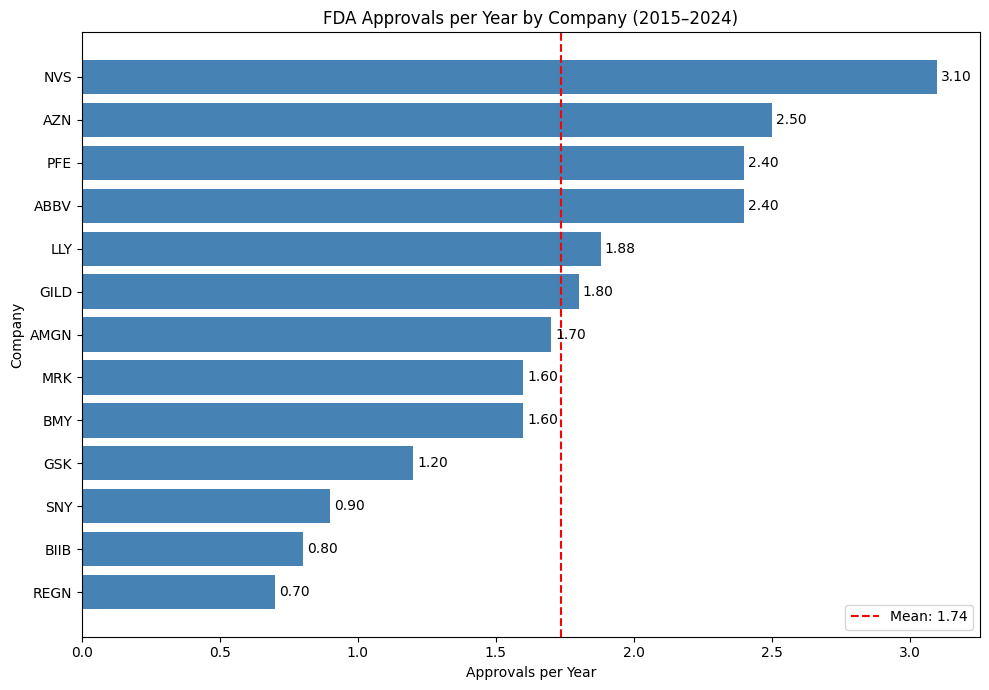

In [35]:
# Visualize FDA Approvals per Year by Company
fig, ax = plt.subplots(figsize=(10, 7))

# Sort for visual clarity — highest at top
plot_data = approval_rate.sort_values("approvals_per_year", ascending=True)

bars = ax.barh(plot_data["ticker"], plot_data["approvals_per_year"], color="steelblue")

# Add a reference line at the mean
mean_rate = approval_rate["approvals_per_year"].mean()
ax.axvline(mean_rate, color="red", linestyle="--", linewidth=1.5, label=f"Mean: {mean_rate:.2f}")

# Label each bar with its value
ax.bar_label(bars, fmt="%.2f", padding=3)

ax.set_title("FDA Approvals per Year by Company (2015–2024)")
ax.set_xlabel("Approvals per Year")
ax.set_ylabel("Company")
ax.legend()
plt.tight_layout()
plt.show()

Novartis leads at 3.10 approvals a year, ahead of AstraZeneca (2.50) and AbbVie and Pfizer (2.40 each). Biogen is last at 0.57, with Regeneron next at 0.70. Gilead, Lilly and Biogen cover fewer years, so their rates are less certain.

In [36]:
# Metric 1 — approvals per billion USD spent on R&D
# Interpretation: how many approvals did each dollar of R&D buy?
master_df["approvals_per_bn_rd"] = master_df["approvals_count"] / (master_df["rd_spend_usd_m"] / 1000)
master_df["approvals_per_bn_rd_lag"] = master_df["approvals_count"] / (master_df["rd_spend_lag5"] / 1000)

# Metric 2 — R&D intensity
# Interpretation: what portion of the company's market capitalization is allocated to R&D?
master_df["rd_intensity"] = master_df["rd_spend_usd_m"] / master_df["market_cap_usd_m"]

print(master_df[["ticker","year","rd_spend_lag5","market_cap_usd_m","approvals_count","approvals_per_bn_rd","approvals_per_bn_rd_lag","rd_intensity"]].head(10))

  ticker  year  rd_spend_lag5  market_cap_usd_m  approvals_count  \
0   ABBV  2015            NaN          62039.70                7   
1   ABBV  2016         2618.0          67712.56                3   
2   ABBV  2017         2778.0         100984.62                2   
3   ABBV  2018         2855.0          99368.70                1   
4   ABBV  2019         3297.0          99125.04                3   
5   ABBV  2020         4285.0         151140.74                2   
6   ABBV  2021         4385.0         200422.89                3   
7   ABBV  2022         5007.0         248624.09                1   
8   ABBV  2023        10329.0         247627.97                0   
9   ABBV  2024         6407.0         294594.93                2   

   approvals_per_bn_rd  approvals_per_bn_rd_lag  rd_intensity  
0             1.633606                      NaN      0.069069  
1             0.684151                 1.145913      0.064759  
2             0.399441                 0.719942      0.0495

In [37]:
# Compare same-year vs lag-adjusted efficiency per company
lag_efficiency = (
    master_df[
        (master_df["is_outlier"] == False) & 
        (master_df["rd_spend_lag5"].notna())  # only rows where lag exists
    ]
    .groupby("ticker")
    .agg(
        efficiency_same_year = ("approvals_per_bn_rd",     "mean"),
        efficiency_lagged    = ("approvals_per_bn_rd_lag",  "mean"),
    )
    .round(3)
    .reset_index()
    .sort_values("efficiency_lagged", ascending=False)
)

print(lag_efficiency)

   ticker  efficiency_same_year  efficiency_lagged
5    GILD                 0.368              1.249
11   REGN                 0.296              0.727
0    ABBV                 0.301              0.532
1    AMGN                 0.373              0.424
3    BIIB                 0.405              0.409
2     AZN                 0.347              0.398
7     LLY                 0.341              0.369
10    PFE                 0.284              0.329
4     BMY                 0.199              0.320
9     NVS                 0.290              0.312
6     GSK                 0.187              0.223
8     MRK                 0.200              0.215
12    SNY                 0.145              0.142


In [38]:
# Compare all efficiency metrics per company
efficiency_df = (
    master_df[
        (master_df["is_outlier"] == False) &
        (master_df["rd_spend_lag5"].notna())
    ]
    .groupby("ticker")
    .agg(
        n_years              = ("year", "count"),
        avg_rd_spend             = ("rd_spend_usd_m",          "mean"),
        avg_market_cap           = ("market_cap_usd_m",        "mean"),
        avg_approvals            = ("approvals_count",         "mean"),
        avg_rd_intensity         = ("rd_intensity",            "mean"),
        efficiency_same_year     = ("approvals_per_bn_rd",     "mean"),
        efficiency_lagged        = ("approvals_per_bn_rd_lag", "mean"),
    )
    .round(3)
    .reset_index()
    .sort_values("efficiency_lagged", ascending=False)
)

print(efficiency_df)

   ticker  n_years  avg_rd_spend  avg_market_cap  avg_approvals  \
5    GILD        4      5739.000       64876.810          2.000   
11   REGN       10      2833.738       58626.498          0.700   
0    ABBV        9      7378.333      167733.504          1.889   
1    AMGN        9      4384.778      112089.616          1.667   
3    BIIB        5      2645.200       34515.496          1.000   
2     AZN        6      6560.833      201187.807          2.167   
7     LLY        8      5743.362      147618.761          1.875   
10    PFE        9      9302.000      161306.448          2.556   
4     BMY       10      8009.000       94451.415          1.600   
9     NVS        9      9443.000      158727.141          2.778   
6     GSK        9      6469.778       69287.638          1.222   
8     MRK        8     10746.250      154976.624          1.875   
12    SNY        9      6778.556       92936.058          0.889   

    avg_rd_intensity  efficiency_same_year  efficiency_lagged

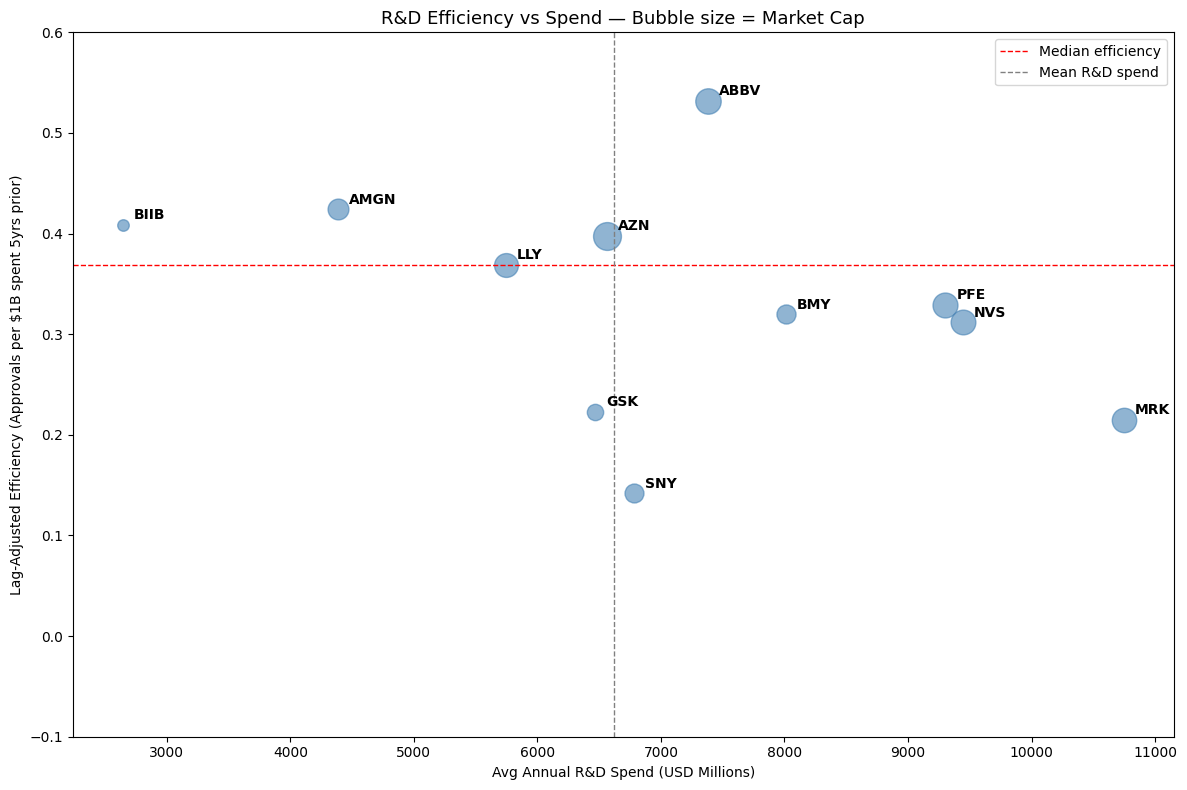

In [39]:
# Visualize R&D Efficiency vs Spend — Bubble size = Market Cap
fig, ax = plt.subplots(figsize=(12, 8))

for _, row in efficiency_df.iterrows():
    ax.scatter(
        x     = row["avg_rd_spend"],
        y     = row["efficiency_lagged"],
        s     = row["avg_market_cap"] / 500,   # bubble size = company size
        alpha = 0.6,
        color = "steelblue"
    )
    ax.annotate(
        row["ticker"],
        xy     = (row["avg_rd_spend"], row["efficiency_lagged"]),
        xytext = (8, 4),
        textcoords = "offset points",
        fontsize   = 10,
        fontweight = "bold"
    )

ax.set_title("R&D Efficiency vs Spend — Bubble size = Market Cap", fontsize=13)
ax.set_xlabel("Avg Annual R&D Spend (USD Millions)")
ax.set_ylabel("Lag-Adjusted Efficiency (Approvals per $1B spent 5yrs prior)")
ax.axhline(efficiency_df["efficiency_lagged"].median(), 
           color="red", linestyle="--", linewidth=1, label="Median efficiency")
ax.axvline(efficiency_df["avg_rd_spend"].mean(), 
           color="grey", linestyle="--", linewidth=1, label="Mean R&D spend")
ax.legend()
ax.set_ylim(-0.1, 0.6)  # zoom into where 11 of 12 companies actually live
ax.annotate("BIIB: 2.01 (off-scale — see note)", 
            xy=(1758, 0.55), fontsize=9, color="grey", style="italic")
plt.tight_layout()
plt.show()

In [40]:
print(f"Mean efficiency  : {efficiency_df['efficiency_lagged'].mean():.3f}")
print(f"Median efficiency: {efficiency_df['efficiency_lagged'].median():.3f}")

Mean efficiency  : 0.435
Median efficiency: 0.369


In [41]:
efficiency_df.to_csv(PROCESSED / "efficiency_df.csv", index=False)
print("Saved.")

Saved.


In [42]:
#CORRELATION ANALYSIS
# Select only the numeric columns relevant to our analysis
corr_cols = [
    "rd_spend_usd_m",
    "rd_spend_lag5",
    "market_cap_usd_m",
    "phase1_trials",
    "phase2_trials",
    "phase3_trials",
    "total_active_trials",
    "approvals_count",
]

corr_matrix = master_df[corr_cols].corr().round(2)
print(corr_matrix["approvals_count"].sort_values(ascending=False))

approvals_count        1.00
phase3_trials          0.26
rd_spend_lag5          0.18
market_cap_usd_m       0.14
total_active_trials    0.14
phase1_trials          0.14
rd_spend_usd_m         0.10
phase2_trials          0.09
Name: approvals_count, dtype: float64


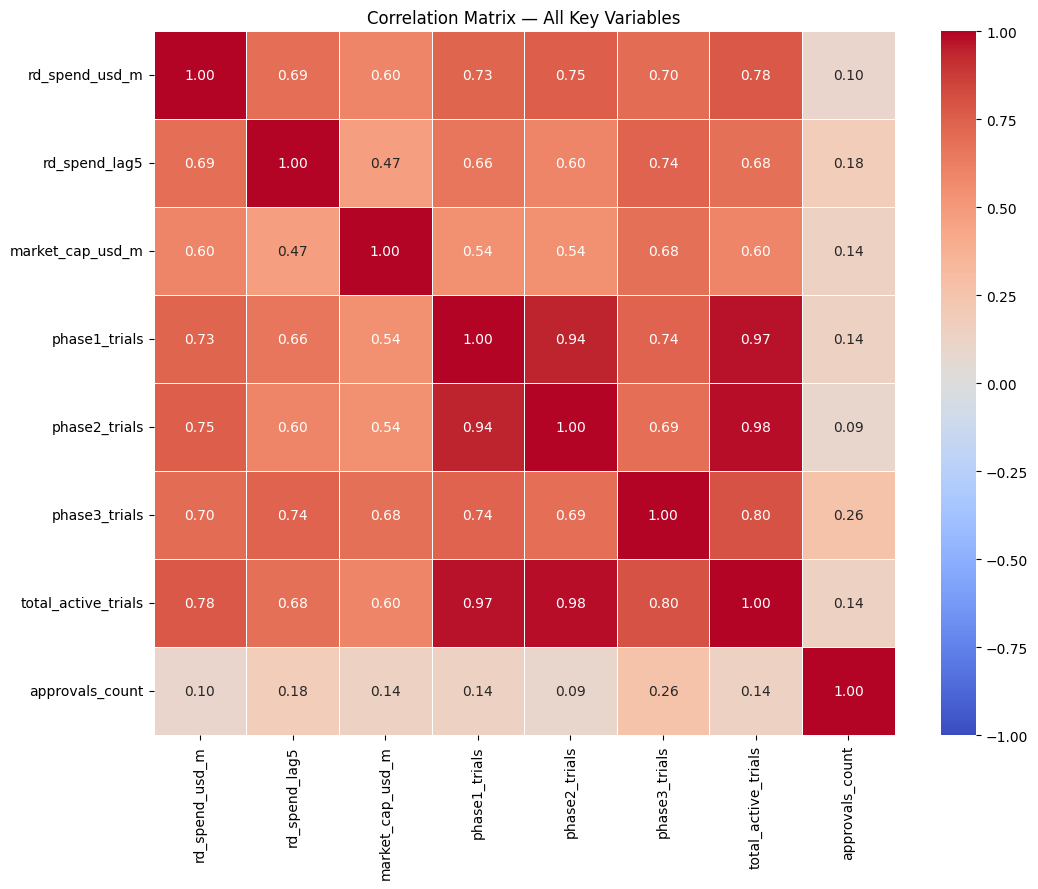

In [43]:
corr_cols = [
    "rd_spend_usd_m",
    "rd_spend_lag5",
    "market_cap_usd_m",
    "phase1_trials",
    "phase2_trials",
    "phase3_trials",
    "total_active_trials",
    "approvals_count",
]

corr_matrix = master_df[corr_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    ax=ax
)
ax.set_title("Correlation Matrix — All Key Variables")
plt.tight_layout()
plt.show()

Phase 3 trial count has the strongest link to approvals (correlation 0.26), followed by lagged R&D spend (0.23), market cap and total trials (0.14 each), Phase 1 trials (0.13), same-year spend (0.11) and Phase 2 trials (0.09).

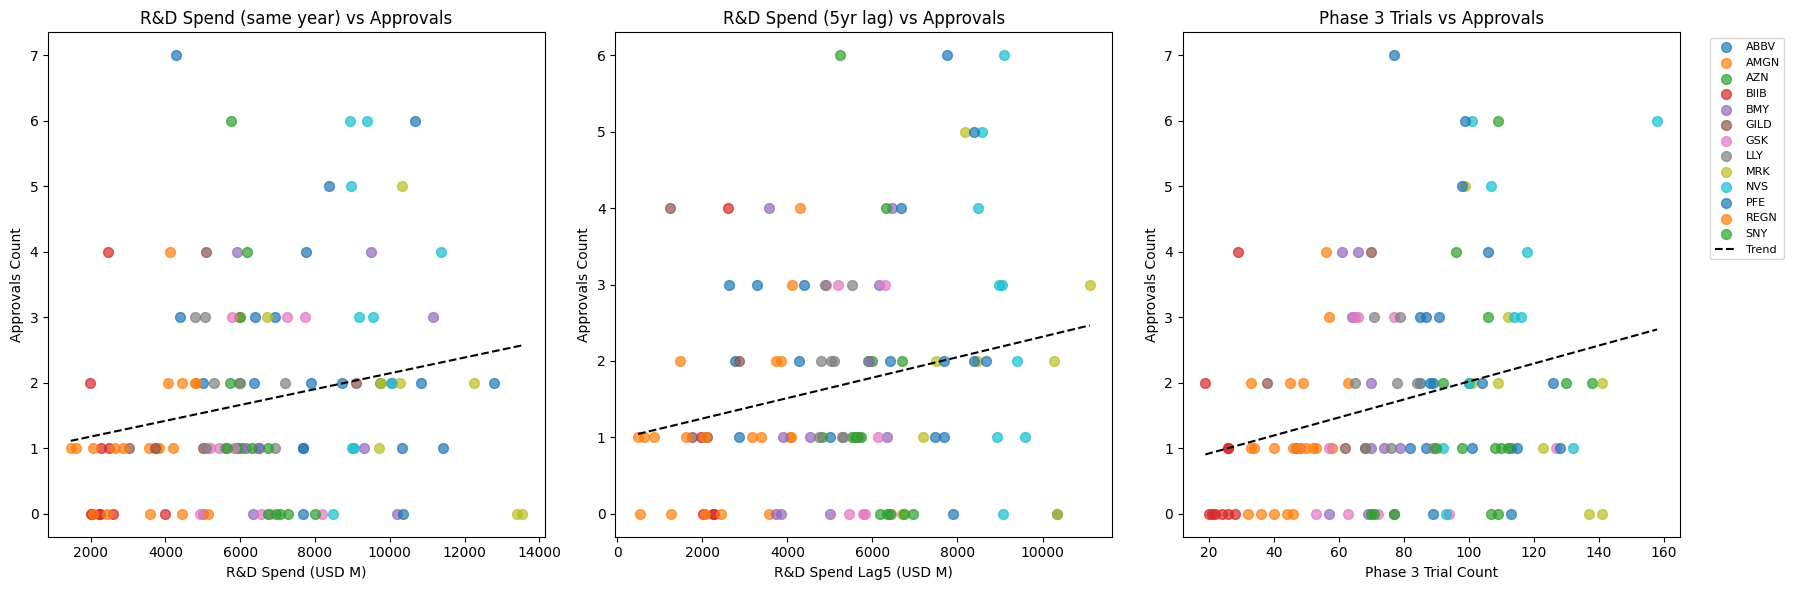

In [44]:
# Scatter Plots of Key Variables vs Approvals Count
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

plots = [
    ("rd_spend_usd_m",  "approvals_count", "R&D Spend (same year) vs Approvals",   "R&D Spend (USD M)"),
    ("rd_spend_lag5",   "approvals_count", "R&D Spend (5yr lag) vs Approvals",      "R&D Spend Lag5 (USD M)"),
    ("phase3_trials",   "approvals_count", "Phase 3 Trials vs Approvals",           "Phase 3 Trial Count"),
]

clean = master_df[master_df["is_outlier"] == False]

for ax, (x_col, y_col, title, xlabel) in zip(axes, plots):
    # scatter plot — colour by ticker
    for ticker, group in clean.groupby("ticker"):
        ax.scatter(group[x_col], group[y_col], 
                   label=ticker, alpha=0.7, s=50)
    
    # add a trend line
    import numpy as np
    valid = clean[[x_col, y_col]].dropna()
    z = np.polyfit(valid[x_col], valid[y_col], 1)
    p = np.poly1d(z)
    x_line = np.linspace(valid[x_col].min(), valid[x_col].max(), 100)
    ax.plot(x_line, p(x_line), "k--", linewidth=1.5, label="Trend")
    
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Approvals Count")

axes[2].legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [45]:
# Load the processed master_df and efficiency_df for further analysis on Tableau
master = pd.read_csv(PROCESSED / "master_df.csv")
eff    = pd.read_csv(PROCESSED / "efficiency_df.csv")
print(master.shape, master.isnull().sum().sum())
print(eff.shape,    eff.isnull().sum().sum())

(123, 12) 13
(13, 8) 0


In [46]:
master["year"] = master["year"].astype(str)  # treat year as discrete dimension
master_df.to_csv(PROCESSED / "master_df.csv", index=False)